# ДЗ 8. Графики для менеджера: Matplotlib и Seaborn
Срок: **до воскресенья 29.11, 24:00**.
Сдача: папка `hw08` репозитория `dsa-homework` (`hw08.ipynb`): `git add hw08` → `git commit` → `git push`, ссылку прикрепите в LMS. Перед сдачей запустите все ячейки, чтобы графики были видны в GitHub.

Каждый график: **заголовок-вывод, подписи осей с единицами, рядом число, которым проверен заголовок**. Под графиком – вывод для менеджера (в print или Markdown-ячейке): что видно и что делать.

Инструменты: всё с уроков 1–8. Если берёте непройденный инструмент, объясните его в комментарии.

- **[База]** обязательно для всех · **[Стандарт]** сколько получится · **[Челлендж]** для тех, кому легко.

## [Для всех] Чтение кода: без запуска
Сначала напишите ответ и «почему», потом запустите.
```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# 1
fig, ax = plt.subplots()
pd.Series([3, 1, 2], index=["a", "b", "c"]).sort_values().plot(kind="bar", ax=ax)
print([t.get_text() for t in ax.get_xticklabels()])
# 2
fig, axes = plt.subplots(1, 3)
print(axes.shape)
# 3
fig, ax = plt.subplots()
sns.barplot(x=["a", "a", "b"], y=[10, 30, 5], ax=ax)
print([float(b.get_height()) for b in ax.patches])
# 4
counts, edges = np.histogram([10, 20, 30, 40], bins=2)
print(counts, edges)
# 5
fig, (a1, a2) = plt.subplots(1, 2)
a1.plot([1, 2], [95, 100])
a2.bar([1, 2], [95, 100])
print(a1.get_ylim()[0] > 0, a2.get_ylim()[0])
```

1. ['c', 'a', 'b'] sort_values() расположит значения 1 2 3 по возрастанию а на оси х окажутся их индексы c a b

2. (1, 3) plt.subplots(1, 3) создаёт массив из трёх областей графика в одном ряду

3. [7.5, 30.0] sns.barplot  показывает среднее для a это (10+5)/2=7.5 для b 30

4. [2 2] [10. 25. 40.] две корзины имеют границы 10-25 и 25-40 в каждой по два числ

5. True 0.0 ось линии с точками 95 и 100 начинается выше нуля а ось столбиков начинается с нуля 
это показывает почему обрезанная ось у линии визуально усиливает небольшие различия

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

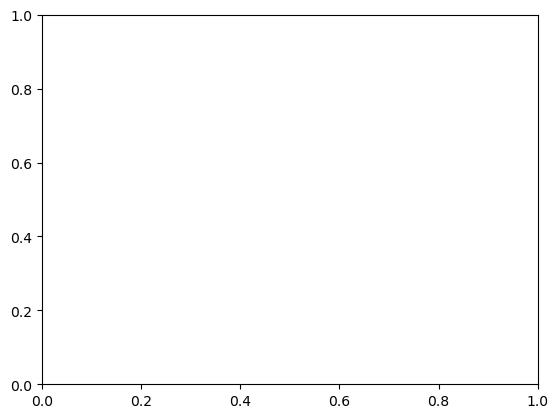

In [4]:
fig, ax = plt.subplots()

In [6]:
pd.Series([3, 1, 2], index=["b", "c", "a"]).sort_values()

c    1
a    2
b    3
dtype: int64

In [9]:
pd.Series([3, 1, 2], index=["a", "b", "c"]).sort_values().plot(kind="bar", ax=ax)
print([t.get_text() for t in ax.get_xticklabels()])

['b', 'c', 'a']


(3,)


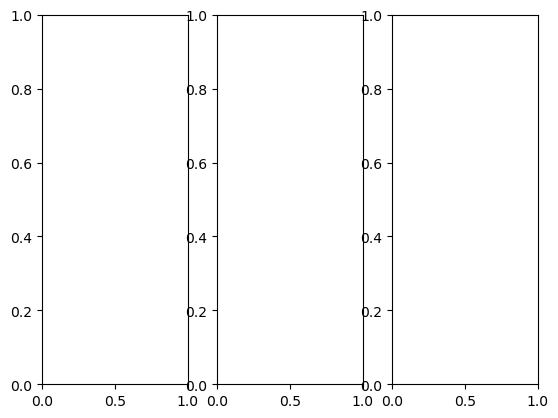

In [2]:
fig, axes = plt.subplots(1, 3)
print(axes.shape)

[20.0, 5.0]


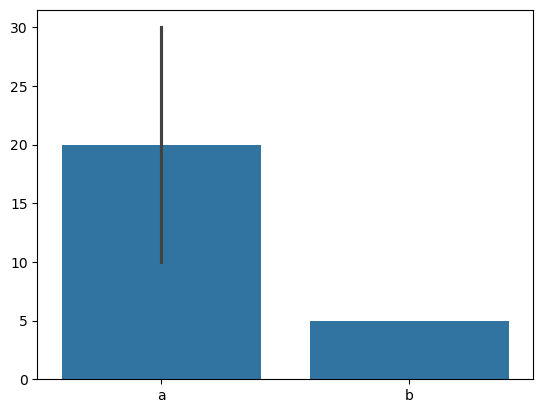

In [3]:
fig, ax = plt.subplots()
sns.barplot(x=["a", "a", "b"], y=[10, 30, 5], ax=ax)
print([float(b.get_height()) for b in ax.patches])

In [4]:
counts, edges = np.histogram([10, 20, 30, 40], bins=2)
print(counts, edges)

[2 2] [10. 25. 40.]


True 0.0


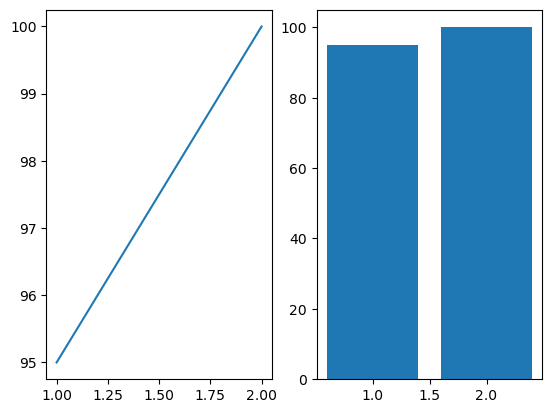

In [5]:
fig, (a1, a2) = plt.subplots(1, 2)
a1.plot([1, 2], [95, 100])
a2.bar([1, 2], [95, 100])
print(a1.get_ylim()[0] > 0, a2.get_ylim()[0])

In [6]:
# Загрузка orders.csv: в Colab нажмите «Выбрать файлы» и укажите orders.csv из LMS.
# Если файл уже лежит рядом с ноутбуком, загрузка пропускается.
import os
if not os.path.exists("orders.csv"):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        print("Положите orders.csv в одну папку с ноутбуком")
print("orders.csv на месте:", os.path.exists("orders.csv"))

orders.csv на месте: True


In [7]:
# Очистка урока 6 одной ячейкой: суммы, города, дубли, даты, TEST
import pandas as pd
import numpy as np

CITY = {"алматы": "Алматы", "almaty": "Алматы", "астана": "Астана", "astana": "Астана",
        "шымкент": "Шымкент", "shymkent": "Шымкент", "караганда": "Караганда",
        "актобе": "Актобе", "атырау": "Атырау"}

df = pd.read_csv("orders.csv")
df["amount"] = pd.to_numeric(df["amount"].str.replace(" ", ""))
df["city"] = df["city"].str.strip().str.lower().map(CITY)
df = df.drop_duplicates()
df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.month
df = df[df["customer_id"] != "TEST"].copy()    # copy: дальше добавим столбцы
df.shape

(5280, 9)

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df["cancel"] = df["status"] == "отменён"     # True/False, урок 7
paid = df[df["status"] == "оплачен"]
len(paid)

4739

Можно вместо ячейки очистки взять свою функцию `clean()` из ДЗ 6. Проверка: 5 280 строк, 4 739 оплаченных.

## [База] 1. Дни недели
В ДЗ 6 меньше всего заказов было в понедельник. Нарисуйте число заказов по дням недели столбиками **в порядке пн → вс** с подписями «пн», «вт», … (подсказка: `.dt.day_of_week` даёт 0 для понедельника, `value_counts().sort_index()`).
Проверьте высоты столбиков (`ax.patches`) против таблицы. Почему `value_counts()` без `sort_index()` здесь не подходит?

In [9]:
days = df["order_date"].dt.day_of_week.value_counts().sort_index()
names = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]

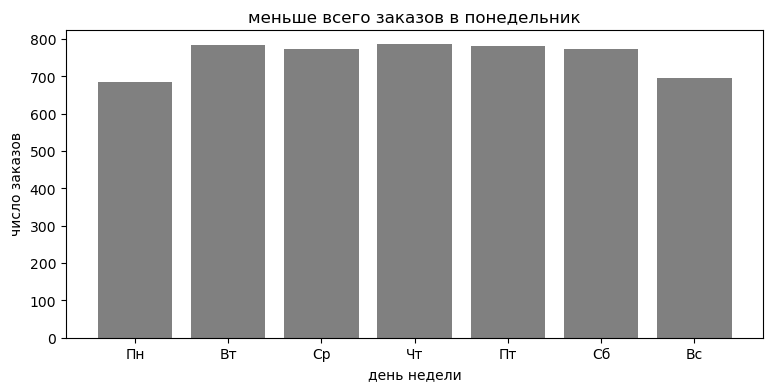

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(names, days.values, color="gray")
ax.set_title("меньше всего заказов в понедельник")
ax.set_xlabel("день недели")
ax.set_ylabel("число заказов")
ax.set_ylim(bottom=0)
plt.show()

In [11]:
days

order_date
0    684
1    785
2    774
3    786
4    781
5    773
6    697
Name: count, dtype: int64

In [15]:
[b.get_height() for b in ax.patches]

[np.int64(684),
 np.int64(785),
 np.int64(774),
 np.int64(786),
 np.int64(781),
 np.int64(773),
 np.int64(697)]

в понедельник было 684 заказа  меньше чем в любой другой день недели
больше всего заказов в четверг  786 разница составляет 102 заказа

## [База] 2. Категории: сентябрь и октябрь
Выручка оплаченных по категориям и месяцам (`pivot_table`, урок 7). Два графика рядом (`plt.subplots(1, 2)`): слева выручка сентября и октября столбиками (`pc[[9, 10]].plot(kind="barh", ax=axes[0])`), справа изменение в %, отсортировано, самая падающая категория цветом.
Какая категория падает сильнее всех? Сходится с ДЗ 4 и ДЗ 7?

In [16]:
pc = paid.pivot_table(
    index="category",
    columns="month",
    values="amount",
    aggfunc="sum"
)

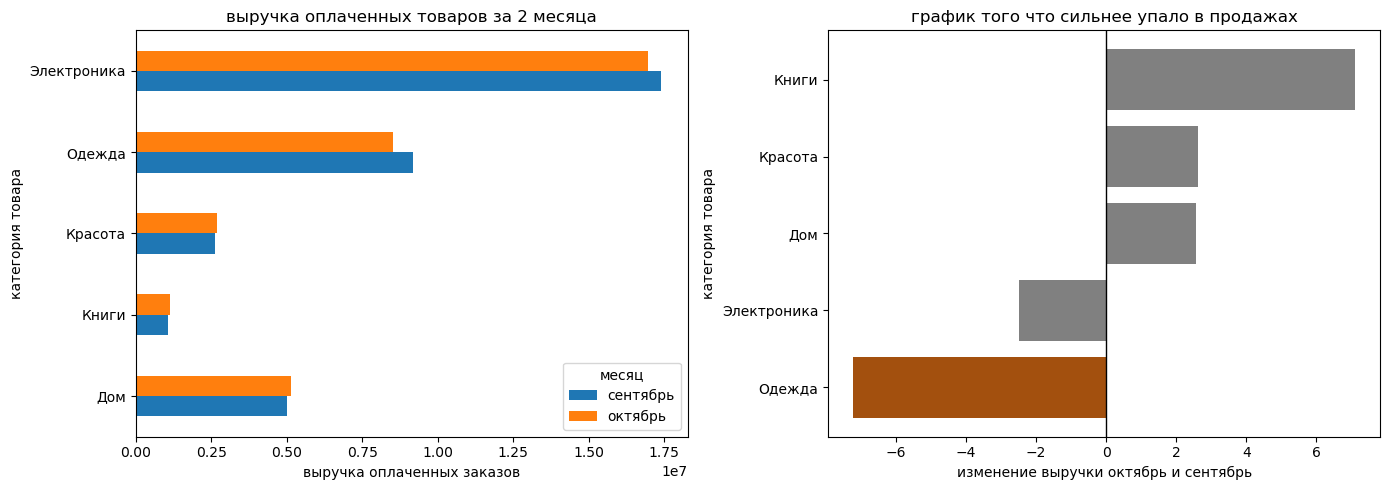

In [21]:
change = ((pc[10] / pc[9] - 1) * 100).sort_values()
colors = ["#A3500E" if category == "Одежда" else "gray"
          for category in change.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pc[[9, 10]].plot(kind="barh", ax=axes[0])
axes[0].set_title("выручка оплаченных товаров за 2 месяца")
axes[0].set_xlabel("выручка оплаченных заказов")
axes[0].set_ylabel("категория товара")
axes[0].legend(title="месяц", labels=["сентябрь", "октябрь"])

axes[1].barh(change.index, change.values, color=colors)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("график того что сильнее упало в продажах")
axes[1].set_xlabel("изменение выручки октябрь и сентябрь")
axes[1].set_ylabel("категория товара")

fig.tight_layout()
plt.show()

In [18]:
pc

month,9,10
category,,
Дом,4997730.0,5125790.0
Книги,1065300.0,1140910.0
Красота,2610950.0,2678990.0
Одежда,9167100.0,8505730.0
Электроника,17402330.0,16968100.0


In [19]:
change.round(1)

category
Одежда        -7.2
Электроника   -2.5
Дом            2.6
Красота        2.6
Книги          7.1
dtype: float64

сильнее всего упала одежда с 9167100 до 8505730 или на 7.2%.
выручка электроники за два месяца 34370430 т.е 34млн после округления это совпадает с дз4

## [База] 3. Выручка компании по дням
Выручка оплаченных по дням линией (`groupby` по `.dt.date`). Отметьте 1 октября вертикальной линией (`ax.axvline`). Найдите день с минимальной и максимальной выручкой.
Видно ли на этом графике падение на 2,3%? Сравните разброс выручки по дням (`std`) с разницей средних за день в сентябре и октябре.

In [22]:
daily_revenue = paid.groupby(paid["order_date"].dt.date)["amount"].sum()
sep_daily = daily_revenue[[date.month == 9 for date in daily_revenue.index]]
oct_daily = daily_revenue[[date.month == 10 for date in daily_revenue.index]]


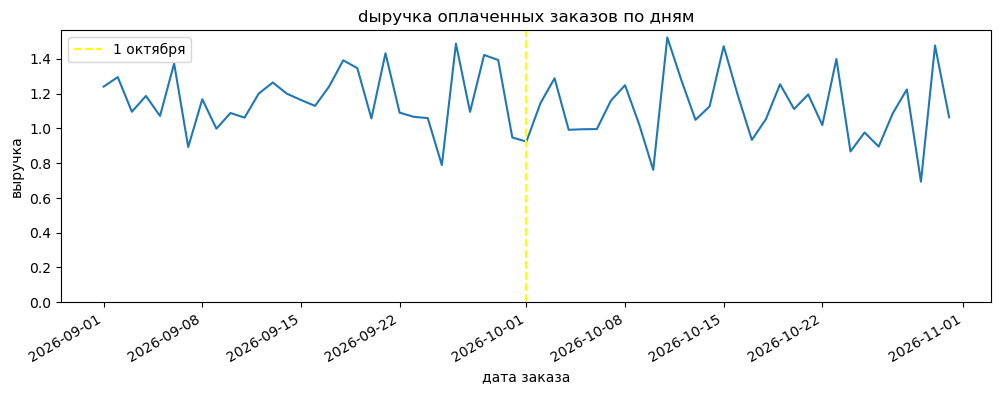

In [26]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily_revenue.index, daily_revenue.values / 1e6)
ax.axvline(pd.Timestamp("2026-10-01"), color="yellow",
           linestyle="--", label="1 октября")
ax.set_title("dыручка оплаченных заказов по дням")
ax.set_xlabel("дата заказа")
ax.set_ylabel("выручка")
ax.set_ylim(bottom=0)
ax.legend()
fig.autofmt_xdate()
plt.show()

In [28]:
daily_revenue.idxmin(), daily_revenue.min()

(datetime.date(2026, 10, 29), 693290.0)

In [29]:
daily_revenue.idxmax(), daily_revenue.max()

(datetime.date(2026, 10, 11), 1523030.0)

In [30]:
sep_daily.mean()

np.float64(1174780.3333333333)

In [31]:
oct_daily.mean()

np.float64(1110307.0967741935)

In [32]:
oct_daily.mean() - sep_daily.mean()

np.float64(-64473.2365591398)

In [33]:
sep_daily.std()

168581.73900951212

In [34]:
oct_daily.std()

199978.74985763774

In [ ]:
минимальная дневная выручка была 29 октября 693290 максимальная 11 октября 1523030
на линии падение месячной выручки на 2.3% отчётливо не видно дневные значения сильно колеблются по обе стороны от 1 октября
средняя выручка за день снизилась с 1174780 в сентябре до 1110307 в октябре разница около 64473 
дневной разброс составляет примерно 168582 в сентябре и 199979 в октябре  оба больше разницы средних
дневные средние нельзя напрямую назвать падением месячной выручки на 2.3% в сентябре 30 дней а в октябре 31

## [Стандарт] 4. Исправьте код от AI
AI нарисовал график и пишет менеджеру: «Выручка в Шымкенте отстаёт от Алматы в разы».
```python
sns.barplot(data=df, x="city", y="amount")
plt.ylim(13500, 15500)
plt.title("Выручка по городам: Шымкент отстаёт в разы")
plt.show()
```
В коде **три** ошибки. Найдите их (проверьте высоты столбиков через `ax.patches`), нарисуйте правильный график выручки и напишите менеджеру, что на самом деле отличает Шымкент: уровень выручки или её изменение?

In [35]:
p = paid.pivot_table(
    index="city", columns="month",
    values="amount", aggfunc="sum"
)

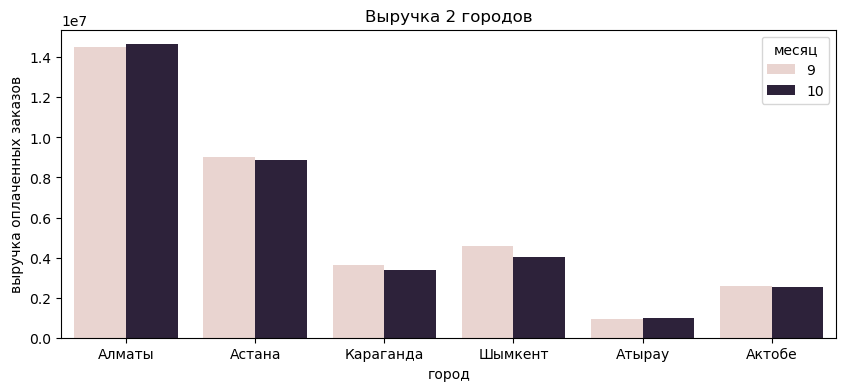

In [40]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(
    data=paid, x="city", y="amount", hue="month",
    estimator="sum", errorbar=None, ax=ax
)
ax.set_ylim(bottom=0)
ax.set_title("Выручка 2 городов")
ax.set_xlabel("город")
ax.set_ylabel("выручка оплаченных заказов")
ax.legend(title="месяц")
plt.show()

In [37]:
p.loc[["Алматы", "Шымкент"]]

month,9,10
city,,
Алматы,14501070.0,14643020.0
Шымкент,4558650.0,4044010.0


In [38]:
[b.get_height() for b in ax.patches]

[np.float64(14501070.0),
 np.float64(9034220.0),
 np.float64(3648520.0),
 np.float64(4558650.0),
 np.float64(923990.0),
 np.float64(2576960.0),
 np.float64(14643020.0),
 np.float64(8850530.0),
 np.float64(3371680.0),
 np.float64(4044010.0),
 np.float64(969860.0),
 np.float64(2540420.0),
 0,
 0]

в коде было три ошибки
sns.barplot(data=df, x="city", y="amount") по умолчанию показывает средний чек
а заголовок называет его выручкой df включает не только оплаченные заказы, поэтому для выручки нужен paid.plt.ylim(13500, 15500) 
обрезает ось у и зрительно преувеличивает различия между столбцами
для выручки нужен график суммы amount по городам среди оплаченных заказов, с осью у от нуля

## [Стандарт] 5. Город или срок доставки?
Тепловая карта «город × срок доставки»: доля отмен (`annot=True`, `fmt=".0%"`). Рядом вторая тепловая карта: число заказов в каждой клетке (`fmt=".0f"`).
Отменяют ли в Шымкенте чаще, чем в других городах, **при одинаковом сроке доставки**? Посчитайте долю отмен в Шымкенте и в остальных городах только для заказов со сроком ≤ 3 дня. Что это значит для решения менеджера?

In [41]:
cancel_rate = df.pivot_table(
    index="city", columns="delivery_days",
    values="cancel", aggfunc="mean"
)
order_count = df.pivot_table(
    index="city", columns="delivery_days",
    values="cancel", aggfunc="size"
)

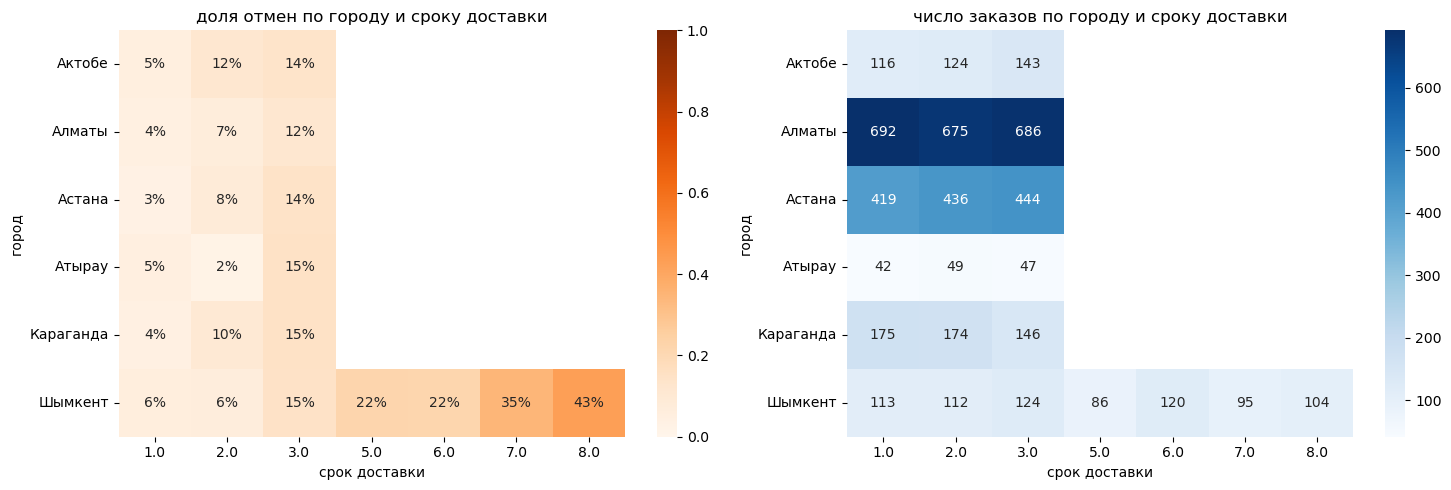

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(
    cancel_rate, annot=True, fmt=".0%", cmap="Oranges",
    vmin=0, vmax=1, ax=axes[0]
)
axes[0].set_title("доля отмен по городу и сроку доставки")
axes[0].set_xlabel("срок доставки")
axes[0].set_ylabel("город")

sns.heatmap(
    order_count, annot=True, fmt=".0f", cmap="Blues",
    ax=axes[1]
)
axes[1].set_title("число заказов по городу и сроку доставки")
axes[1].set_xlabel("срок доставки")
axes[1].set_ylabel("город")

fig.tight_layout()
plt.show()

In [43]:
short = df[df["delivery_days"] <= 3].copy()
short["group"] = np.where(
    short["city"] == "Шымкент", "Шымкент", "Другие города"
)

comparison = short.groupby("group")["cancel"].agg(
    orders="size",
    cancelled="sum",
    cancel_share="mean"
)
comparison["cancel_share"] = (comparison["cancel_share"] * 100).round(1)
print(comparison)

               orders  cancelled  cancel_share
group                                         
Другие города    4368        372           8.5
Шымкент           349         32           9.2


при сроке доставки до 3 дней доля отмен в Шымкенте 9.2%
в остальных городах 8.5% разница составляет всего 0.7 процентного пункта 
на тепловой карте при доставке за 5–8 дней доля отмен в шымкенте выше от 22% до 43% 
среди заказов с короткой доставкой шымкент почти не отличается от остальных городов по доле отмен

## [Стандарт] 6. Выбросы на ящике с усами
Ящик с усами: чек оплаченных по категориям. Посчитайте, сколько точек-выбросов в каждой категории по правилу 1,5 IQR (`groupby("category")["amount"].quantile(0.25)` и `0.75`).
В ДЗ 5 одна граница на всех (около 38 тыс. ₸) записала в выбросы почти только Электронику. Сколько выбросов теперь и в каких категориях? Какой подход честнее и почему?

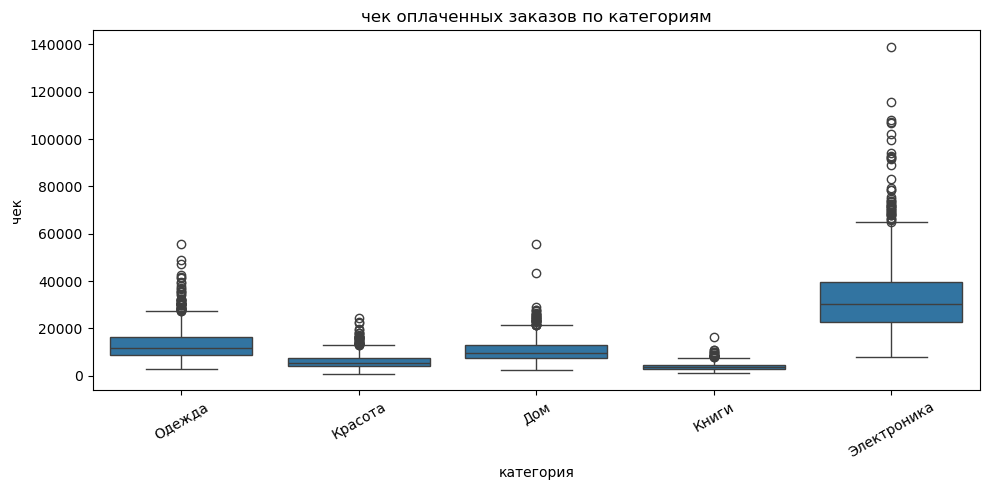

In [47]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=paid, x="category", y="amount", ax=ax)
ax.set_title("чек оплаченных заказов по категориям")
ax.set_xlabel("категория")
ax.set_ylabel("чек")
plt.xticks(rotation=30)
fig.tight_layout()
plt.show()

In [46]:
q1 = paid.groupby("category")["amount"].quantile(0.25)
q3 = paid.groupby("category")["amount"].quantile(0.75)
lower = q1 - 1.5 * (q3 - q1)
upper = q3 + 1.5 * (q3 - q1)

result = pd.DataFrame({
    "заказов": paid.groupby("category").size(),
    "выбросов_по_категории": paid.groupby("category")["amount"].apply(
        lambda s: ((s < lower.loc[s.name]) | (s > upper.loc[s.name])).sum()
    ),
    "выбросов_свыше_38000": paid.groupby("category")["amount"].apply(
        lambda s: (s > 38000).sum()
    )
})
print(result)
print("\nВсего выбросов по границам категорий:",
      result["выбросов_по_категории"].sum())

             заказов  выбросов_по_категории  выбросов_свыше_38000
category                                                         
Дом              952                     32                     2
Книги            564                     18                     0
Красота          857                     35                     0
Одежда          1330                     48                     9
Электроника     1036                     43                   297

Всего выбросов по границам категорий: 176


по правилу 1.5*IQR рассчитанному отдельно для каждой категории
получилось 176 выбросов одежда 48 электроника 43 красота 35 дом 32 книги 18
для сравнения необычных чеков между категориями этот подход честнее он учитывает их разные уровни цен
общая граница 38тыс отметила 308 заказов из которых 297 относятся к электронике поскольку её чеки обычно выше

## [Челлендж] 7. Две оси от AI
AI нарисовал по Шымкенту заказы в день и выручку в день на двух осях (`ax.twinx()`) и пишет: «Линии идут вместе, всё в порядке». Две оси позволяют подогнать любые две линии друг к другу.
Нарисуйте честно, на одной оси: число заказов в день и выручку оплаченных в день в Шымкенте, обе как **индекс к среднему дню сентября = 100**. Какой индекс у каждой линии в среднем за октябрь? Что это говорит об отменах?

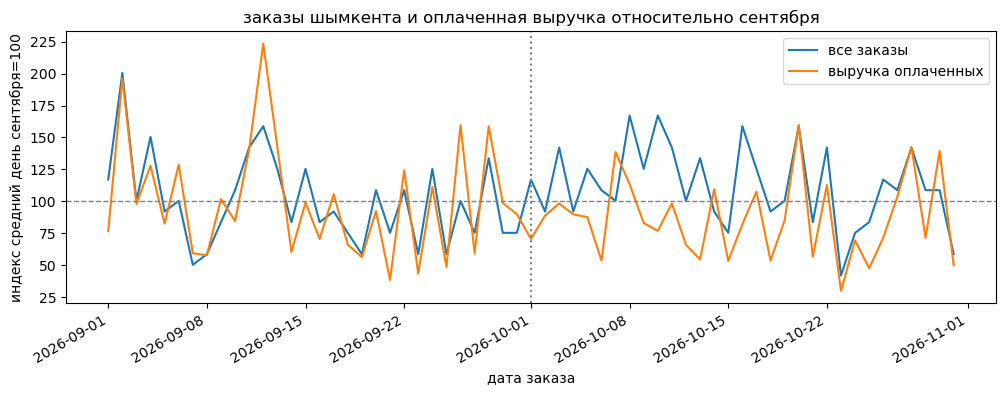

In [60]:
sh_orders = (
    df[df["city"] == "Шымкент"]
    .groupby(df["order_date"].dt.normalize())
    .size()
)
sh_revenue = (
    paid[paid["city"] == "Шымкент"]
    .groupby(paid["order_date"].dt.normalize())["amount"]
    .sum()
)
dates = pd.date_range("2026-09-01", "2026-10-31", freq="D")
daily = pd.DataFrame({
    "orders": sh_orders.reindex(dates, fill_value=0),
    "revenue": sh_revenue.reindex(dates, fill_value=0)
})
sep_mean = daily.loc["2026-09", ["orders", "revenue"]].mean()
indexed = daily[["orders", "revenue"]].div(sep_mean).mul(100)
oct_mean_index = indexed.loc["2026-10"].mean()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(indexed.index, indexed["orders"], label="все заказы")
ax.plot(indexed.index, indexed["revenue"], label="выручка оплаченных")
ax.axhline(100, color="gray", linestyle="--", linewidth=1)
ax.axvline(pd.Timestamp("2026-10-01"), color="gray", linestyle=":")
ax.set_title("заказы шымкента и оплаченная выручка относительно сентября")
ax.set_xlabel("дата заказа")
ax.set_ylabel("индекс средний день сентября=100")
ax.legend()
fig.autofmt_xdate()
plt.show()

In [61]:
print(oct_mean_index.round(1))
print(
    (df[df["city"] == "Шымкент"]
     .groupby("month")["cancel"].mean() * 100).round(1)
)

orders     112.4
revenue     85.8
dtype: float64
month
9      8.9
10    30.7
Name: cancel, dtype: float64


orders считает все заказы а revenue только оплаченные
если в октябре индекс заказов остаётся около 100 а индекс выручки падает это совместимо с ростом отмен

## [Челлендж] 8. Plotly: найти момент сбоя
Точечный график заказов Шымкента 28.09–03.10: `px.scatter(x="order_date", y="delivery_days", color="status", hover_data=["order_id"])`. Наведением найдите последний заказ с быстрой доставкой (≤ 3 дня) и первый медленный (≥ 5 дней).
Проверьте ответ кодом Pandas (фильтр и `sort_values`). GitHub не покажет график Plotly, поэтому ответ напишите текстом.

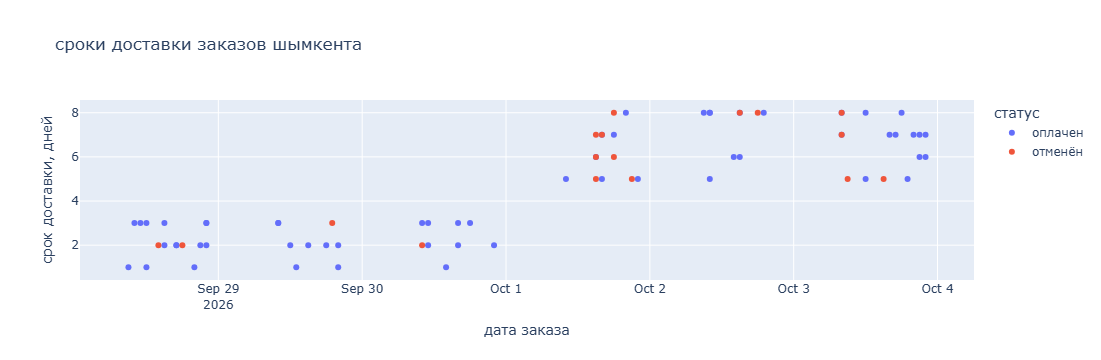

In [58]:
sh_period = df[
    (df["city"] == "Шымкент")
    & (df["order_date"].dt.normalize() >= "2026-09-28")
    & (df["order_date"].dt.normalize() <= "2026-10-03")
].copy()

fig = px.scatter(
    sh_period,
    x="order_date",
    y="delivery_days",
    color="status",
    hover_data=["order_id"],
    title="сроки доставки заказов шымкента",
    labels={
        "order_date": "дата заказа",
        "delivery_days": "срок доставки, дней",
        "status": "статус"
    }
)
fig.show()

In [59]:
sh_sorted = sh_period.sort_values(["order_date", "order_id"])
first_slow = sh_sorted[sh_sorted["delivery_days"] >= 5].iloc[0]

before_slow = sh_sorted[
    (sh_sorted["order_date"] < first_slow["order_date"])
    | (
        (sh_sorted["order_date"] == first_slow["order_date"])
        & (sh_sorted["order_id"] < first_slow["order_id"])
    )
]
last_fast = before_slow[before_slow["delivery_days"] <= 3].iloc[-1]
print(last_fast[["order_id", "order_date", "delivery_days", "status"]])
print(first_slow[["order_id", "order_date", "delivery_days", "status"]])

order_id                      101246
order_date       2026-09-30 22:00:00
delivery_days                    2.0
status                       оплачен
Name: 2780, dtype: object
order_id                      104543
order_date       2026-10-01 10:00:00
delivery_days                    5.0
status                       оплачен
Name: 2793, dtype: object


In [ ]:
последний заказ шымкента с быстрой доставкой 101246 от 30 сентября 2026 года 22:00 срок 2 дня
первый заказ с доставкой от 5 дней 104543 от 1 октября 2026 года 10:00 срок 5 дней
таким образом переход к долгой доставке в данных наблюдается между этими заказами 
оба заказа оплачены причина изменения срока по графику и таблице неизвестна